# Marine Spatial Planning Violation Signals

Colab/Jupyter notebook using Google Earth Engine and `geemap` to flag coastal changes that may indicate marine spatial planning violations.

The outputs are **review signals, not legal conclusions**. Every flagged zone needs checking by a planner, regulator, or domain expert.

Cells whose first line is `# lib-cell: ...` contain only imports, constants, and function definitions. The tests in `scripts/` load and check exactly those cells, so keep side effects (map display, `getInfo()` calls) out of them.

## 1. Install and import packages

In Colab, run the install cell first. Locally, run `pip install -r requirements.txt` once and skip it.

In [1]:
%pip install -q earthengine-api geemap geopandas pandas python-dotenv shapely matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# lib-cell: imports
import calendar
import datetime as dt

import ee
import pandas as pd

In [3]:
import geemap
import matplotlib.pyplot as plt

In [5]:
import os

try:
    from dotenv import load_dotenv

    load_dotenv()  # picks up .env next to the notebook when run locally
except ImportError:
    pass

# Google Cloud project registered for Earth Engine. Set EE_PROJECT in .env (see .env.example),
# or type it here when running in Colab, e.g. EE_PROJECT = "my-ee-project".
EE_PROJECT = os.environ.get("EE_PROJECT", "")

try:
    ee.Initialize(project=EE_PROJECT or None)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT or None)

## 2. Analysis parameters

Thresholds are starting points. Tune them per site: turbid water, tides, and seasonal vegetation all shift index values.

In [6]:
START_DATE = "2022-01-01"
END_DATE = "2024-01-01"
INTERVAL_MONTHS = 6  # use 3 or 6
CLOUD_PROBABILITY_THRESHOLD = 40
NDWI_THRESHOLD = 0.0

# Concern-zone rules
VEGETATED_NDVI = 0.3  # pixel counts as vegetated in the start composite above this NDVI
NDVI_LOSS_THRESHOLD = -0.2  # vegetation loss when NDVI drops by more than this
NDBI_GAIN_THRESHOLD = 0.1  # built-up gain when NDBI rises by more than this
REEF_BUFFER_M = 500  # flagged change within this distance of a mapped reef is marked near_reef
MIN_ZONE_AREA_HA = 0.5  # drop concern zones smaller than this

ANALYSIS_SCALE = 10  # metres; raise to 20-30 for large areas if Earth Engine times out

## 3. Draw or load the coverage area

Draw a polygon on the map using the left toolbar, then run the next cell to capture it as `aoi`. If nothing is drawn, the notebook uses the fallback polygon (Jakarta Bay). Users elsewhere can replace `FALLBACK_COORDS` or the map center.

In [7]:
MAP_CENTER = [-6.2, 106.8]  # lat, lon
FALLBACK_COORDS = [
    [106.70, -6.10],
    [106.90, -6.10],
    [106.90, -6.30],
    [106.70, -6.30],
    [106.70, -6.10],
]

Map = geemap.Map(center=MAP_CENTER, zoom=10)
Map.add_basemap("SATELLITE")
Map

Map(center=[-6.2, 106.8], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [9]:
aoi = Map.user_roi
if aoi is None:
    aoi = ee.Geometry.Polygon([FALLBACK_COORDS])
    print("No drawn AOI found. Using fallback example polygon.")
else:
    print("Using drawn AOI from geemap.")

Map.addLayer(aoi, {"color": "yellow"}, "AOI")
Map.centerObject(aoi, 11)

Using drawn AOI from geemap.


## 4. Helper functions

In [10]:
# lib-cell: date windows
def add_months(date, months):
    """Shift a date by whole months, clamping the day to the target month's length."""
    month_index = date.month - 1 + months
    year = date.year + month_index // 12
    month = month_index % 12 + 1
    day = min(date.day, calendar.monthrange(year, month)[1])
    return dt.date(year, month, day)


def date_windows(start_date, end_date, interval_months=3):
    """Split [start_date, end_date) into consecutive windows of interval_months.

    Every boundary is measured from start_date, so clamping (e.g. Jan 31 -> Feb 28)
    does not drift into later windows. The last window is cut off at end_date.
    """
    start = dt.date.fromisoformat(start_date)
    end = dt.date.fromisoformat(end_date)
    if interval_months < 1:
        raise ValueError("interval_months must be at least 1")
    if start >= end:
        raise ValueError("start_date must be before end_date")

    windows = []
    current = start
    step = 0
    while current < end:
        step += 1
        next_date = min(add_months(start, step * interval_months), end)
        windows.append((current.isoformat(), next_date.isoformat()))
        current = next_date

    return windows

In [11]:
# lib-cell: Sentinel-2 composites
INDEX_NAMES = ["NDVI", "NDWI", "NDBI"]
CLOUDY_SCL_CLASSES = [3, 8, 9, 10, 11]  # cloud shadow, cloud medium/high probability, cirrus, snow


def sentinel2_collection(aoi, start_date, end_date, cloud_probability_threshold=40):
    """Cloud-masked Sentinel-2 SR images (reflectance 0-1) over aoi between the dates."""
    s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi).filterDate(start_date, end_date)
    clouds = ee.ImageCollection("COPERNICUS/S2_CLOUD_PROBABILITY").filterBounds(aoi).filterDate(start_date, end_date)

    joined = ee.ImageCollection(
        ee.Join.saveFirst("cloud_mask").apply(
            primary=s2,
            secondary=clouds,
            condition=ee.Filter.equals(leftField="system:index", rightField="system:index"),
        )
    )

    def mask_clouds(image):
        cloud_prob = ee.Image(image.get("cloud_mask")).select("probability")
        clear_scl = image.select("SCL").remap(CLOUDY_SCL_CLASSES, [0] * len(CLOUDY_SCL_CLASSES), 1)
        clear = cloud_prob.lt(cloud_probability_threshold).And(clear_scl)
        return image.select("B.*").updateMask(clear).divide(10000).copyProperties(image, ["system:time_start"])

    return joined.map(mask_clouds)


def window_image_counts(aoi, windows, cloud_probability_threshold=40):
    """Number of Sentinel-2 images in each (start, end) window, fetched in one request."""
    counts = ee.List(
        [sentinel2_collection(aoi, start, end, cloud_probability_threshold).size() for start, end in windows]
    )
    return counts.getInfo()


def add_indices(image):
    ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
    ndwi = image.normalizedDifference(["B3", "B8"]).rename("NDWI")
    ndbi = image.normalizedDifference(["B11", "B8"]).rename("NDBI")
    return image.addBands([ndvi, ndwi, ndbi])


def make_composite(aoi, start_date, end_date, cloud_probability_threshold=40):
    """Median composite with NDVI/NDWI/NDBI bands. The window must contain at least one image."""
    collection = sentinel2_collection(aoi, start_date, end_date, cloud_probability_threshold)
    return add_indices(collection.median().clip(aoi)).set(
        {"window_start": start_date, "window_end": end_date, "image_count": collection.size()}
    )

In [12]:
# lib-cell: change detection
def index_change(start_image, end_image):
    """End minus start for each index, as bands NDVI_change, NDWI_change, NDBI_change."""
    return (
        end_image.select(INDEX_NAMES)
        .subtract(start_image.select(INDEX_NAMES))
        .rename([f"{name}_change" for name in INDEX_NAMES])
    )


def water_mask(image, ndwi_threshold=0.0):
    return image.select("NDWI").gt(ndwi_threshold).rename("water")


def water_transitions(start_image, end_image, ndwi_threshold=0.0):
    """Bands water_to_land and land_to_water (0/1) between two composites."""
    start_water = water_mask(start_image, ndwi_threshold)
    end_water = water_mask(end_image, ndwi_threshold)
    return ee.Image.cat(
        [
            start_water.And(end_water.Not()).rename("water_to_land"),
            start_water.Not().And(end_water).rename("land_to_water"),
        ]
    )


def area_ha(mask_image, region, scale=10):
    """ee.Dictionary of hectares covered by each 0/1 band of mask_image within region."""
    return mask_image.multiply(ee.Image.pixelArea().divide(10000)).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=region, scale=scale, maxPixels=1e13
    )


def features_to_frame(feature_collection_info):
    """DataFrame of feature properties from a FeatureCollection getInfo() result."""
    return pd.DataFrame([feature["properties"] for feature in feature_collection_info["features"]])

In [13]:
# lib-cell: time-series summary
def window_stats(image, aoi, ndwi_threshold=0.0, scale=10):
    """ee.Feature with mean indices, water area, and clear-sky fraction for one composite."""
    means = image.select(INDEX_NAMES).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=aoi, scale=scale, maxPixels=1e13
    )
    water = area_ha(water_mask(image, ndwi_threshold).rename("water_ha"), aoi, scale)
    clear = area_ha(image.select("NDWI").mask().gt(0).rename("clear_ha"), aoi, scale)
    aoi_ha = aoi.area(1).divide(10000)
    return ee.Feature(
        None,
        means.combine(water)
        .combine(clear)
        .set("aoi_ha", aoi_ha)
        .set("clear_fraction", ee.Number(clear.get("clear_ha")).divide(aoi_ha))
        .set("window_start", image.get("window_start"))
        .set("window_end", image.get("window_end"))
        .set("image_count", image.get("image_count")),
    )


def time_series_table(composites, aoi, ndwi_threshold=0.0, scale=10):
    """One row per composite, fetched in a single request and sorted by window_start."""
    stats = ee.FeatureCollection([window_stats(image, aoi, ndwi_threshold, scale) for image in composites])
    columns = ["window_start", "window_end", "image_count", "clear_fraction", *INDEX_NAMES, "water_ha", "aoi_ha"]
    return features_to_frame(stats.getInfo()).reindex(columns=columns).sort_values("window_start").reset_index(drop=True)

In [14]:
# lib-cell: Allen Coral Atlas
CORAL_ATLAS_ASSET = "ACA/reef_habitat/v2_0"
GEOMORPHIC_CLASSES = {
    11: "Shallow Lagoon",
    12: "Deep Lagoon",
    13: "Inner Reef Flat",
    14: "Outer Reef Flat",
    15: "Reef Crest",
    16: "Terrestrial Reef Flat",
    21: "Sheltered Reef Slope",
    22: "Reef Slope",
    23: "Plateau",
    24: "Back Reef Slope",
    25: "Patch Reef",
}
BENTHIC_CLASSES = {
    11: "Sand",
    12: "Rubble",
    13: "Rock",
    14: "Seagrass",
    15: "Coral/Algae",
    18: "Microalgal Mats",
}


def coral_atlas():
    """Allen Coral Atlas image with bands geomorphic, benthic, reef_mask (0 = unmapped / not reef)."""
    return ee.Image(CORAL_ATLAS_ASSET)


def class_area_groups(class_image, region, scale=10):
    """Hectares per non-zero class value of a single-band image, as a list of {"class", "sum"} dicts."""
    result = (
        ee.Image.pixelArea()
        .divide(10000)
        .addBands(class_image.selfMask())
        .reduceRegion(
            reducer=ee.Reducer.sum().group(groupField=1, groupName="class"),
            geometry=region,
            scale=scale,
            maxPixels=1e13,
        )
    )
    return result.get("groups")


def class_area_table(groups, class_names):
    """DataFrame of class name and hectares, largest first, from class_area_groups(...).getInfo()."""
    rows = [
        {"class": group["class"], "name": class_names.get(group["class"], "Unknown"), "area_ha": group["sum"]}
        for group in groups
    ]
    frame = pd.DataFrame(rows, columns=["class", "name", "area_ha"])
    return frame.sort_values("area_ha", ascending=False).reset_index(drop=True)


def near_reef_mask(buffer_m=500):
    """0/1 image: 1 within buffer_m metres of an Allen Coral Atlas reef pixel."""
    reef = coral_atlas().select("reef_mask").unmask(0).eq(1)
    distance = reef.distance(ee.Kernel.euclidean(buffer_m, "meters"))
    return distance.lte(buffer_m).unmask(0).rename("near_reef")

In [15]:
# lib-cell: concern flags and zones
FLAG_BANDS = ["water_to_land", "vegetation_loss", "builtup_gain"]


def concern_flags(
    start_image,
    end_image,
    ndwi_threshold=0.0,
    vegetated_ndvi=0.3,
    ndvi_loss_threshold=-0.2,
    ndbi_gain_threshold=0.1,
):
    """0/1 bands water_to_land, vegetation_loss, builtup_gain between two composites.

    Vegetation loss only counts pixels vegetated at the start, and built-up gain only
    counts pixels that are land at the end, so noisy index changes over water are ignored.
    """
    change = index_change(start_image, end_image)
    end_land = water_mask(end_image, ndwi_threshold).Not()
    return ee.Image.cat(
        [
            water_transitions(start_image, end_image, ndwi_threshold).select("water_to_land"),
            start_image.select("NDVI")
            .gt(vegetated_ndvi)
            .And(change.select("NDVI_change").lt(ndvi_loss_threshold))
            .rename("vegetation_loss"),
            end_land.And(change.select("NDBI_change").gt(ndbi_gain_threshold)).rename("builtup_gain"),
        ]
    )


def concern_zones(flags, aoi, near_reef=None, scale=10, min_area_ha=0.5, max_zones=500):
    """Polygons of connected flagged pixels, with hectares of each signal inside them.

    Each zone gets zone_ha, <flag>_ha for every flag band, near_reef_ha (when near_reef
    is given), and centroid lon/lat. Zones are sorted largest first.
    """
    any_flag = flags.reduce(ee.Reducer.max()).rename("any_flag").toInt()
    zones = any_flag.selfMask().reduceToVectors(
        geometry=aoi,
        scale=scale,
        geometryType="polygon",
        eightConnected=True,
        labelProperty="any_flag",
        maxPixels=1e13,
    )

    measured = any_flag.rename("zone").addBands(flags)
    if near_reef is not None:
        measured = measured.addBands(any_flag.And(near_reef).rename("near_reef"))
    hectares = measured.unmask(0).multiply(ee.Image.pixelArea().divide(10000))
    hectares = hectares.rename(measured.bandNames().map(lambda name: ee.String(name).cat("_ha")))

    def add_centroid(zone):
        coords = zone.geometry().centroid(1).coordinates()
        return zone.set({"lon": coords.get(0), "lat": coords.get(1)})

    return (
        hectares.reduceRegions(collection=zones, reducer=ee.Reducer.sum(), scale=scale)
        .filter(ee.Filter.gte("zone_ha", min_area_ha))
        .sort("zone_ha", False)
        .limit(max_zones)
        .map(add_centroid)
    )


def zone_table(zones_info, min_signal_ha=0.0):
    """DataFrame of concern zones from concern_zones(...).getInfo(), with signal summary columns."""
    frame = features_to_frame(zones_info)
    signal_columns = [f"{band}_ha" for band in FLAG_BANDS]
    if frame.empty:
        return pd.DataFrame(columns=["zone_id", "zone_ha", *signal_columns, "signals", "signal_count", "lon", "lat"])

    present = frame[signal_columns].gt(min_signal_ha)
    frame["signals"] = present.apply(
        lambda row: ", ".join(band for band, column in zip(FLAG_BANDS, signal_columns) if row[column]), axis=1
    )
    frame["signal_count"] = present.sum(axis=1)
    frame["zone_id"] = range(1, len(frame) + 1)

    columns = ["zone_id", "zone_ha", *signal_columns]
    if "near_reef_ha" in frame:
        columns.append("near_reef_ha")
    columns += ["signals", "signal_count", "lon", "lat"]
    return frame[columns].sort_values(["signal_count", "zone_ha"], ascending=False).reset_index(drop=True)

## 5. Build the cloud-masked time series

Windows with no Sentinel-2 images are skipped. A window can still have images but very little clear sky, so check `clear_fraction` in the next section before trusting a window's water area.

In [16]:
windows = date_windows(START_DATE, END_DATE, INTERVAL_MONTHS)
counts = window_image_counts(aoi, windows, CLOUD_PROBABILITY_THRESHOLD)

window_table = pd.DataFrame(windows, columns=["window_start", "window_end"]).assign(sentinel2_image_count=counts)
valid_windows = [window for window, count in zip(windows, counts) if count > 0]
skipped = len(windows) - len(valid_windows)
if skipped:
    print(f"Skipping {skipped} window(s) with no Sentinel-2 images.")
if len(valid_windows) < 2:
    raise RuntimeError("Need at least two windows with Sentinel-2 images. Widen the dates or the interval.")

composites = [make_composite(aoi, start, end, CLOUD_PROBABILITY_THRESHOLD) for start, end in valid_windows]
window_table

,window_start,window_end,sentinel2_image_count
0,2022-01-01,2022-07-01,35
1,2022-07-01,2023-01-01,37
2,2023-01-01,2023-07-01,36
3,2023-07-01,2024-01-01,36


## 6. Time-series summary

Mean index values and water area for every window, not just the first and last. Water area drops when clouds hide water, so read it together with `clear_fraction`.

In [17]:
time_series = time_series_table(composites, aoi, NDWI_THRESHOLD, ANALYSIS_SCALE)
time_series

,window_start,window_end,image_count,clear_fraction,NDVI,NDWI,NDBI,water_ha,aoi_ha
0,2022-01-01,2022-07-01,35,0.995742,-0.110817,0.313848,-0.145249,32437.435277,41090.386557
1,2022-07-01,2023-01-01,37,0.995551,-0.116200,0.299159,-0.235632,32626.993084,41090.386557
2,2023-01-01,2023-07-01,36,0.995663,-0.123695,0.309483,-0.188434,32233.281991,41090.386557
3,2023-07-01,2024-01-01,36,0.995745,-0.131688,0.292607,-0.189283,31945.604278,41090.386557


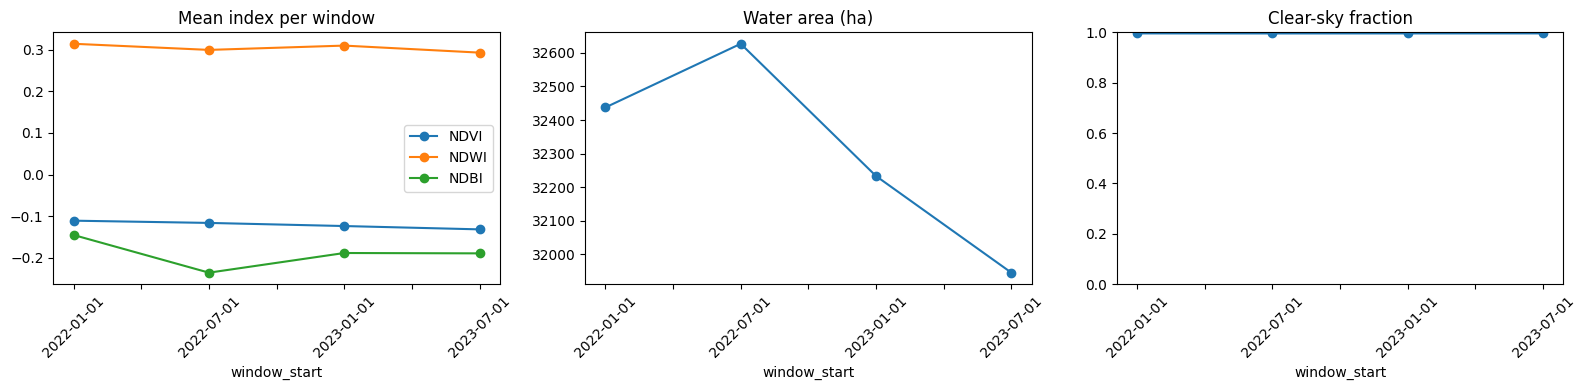

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
time_series.plot(x="window_start", y=INDEX_NAMES, marker="o", ax=axes[0], title="Mean index per window")
time_series.plot(x="window_start", y="water_ha", marker="o", ax=axes[1], legend=False, title="Water area (ha)")
time_series.plot(x="window_start", y="clear_fraction", marker="o", ax=axes[2], legend=False, title="Clear-sky fraction")
axes[2].set_ylim(0, 1)
for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

## 7. Map index changes

Compares the first and last valid windows.

In [19]:
start_image = composites[0]
end_image = composites[-1]
change = index_change(start_image, end_image)

change_map = geemap.Map()
change_map.centerObject(aoi, 11)
change_map.add_basemap("SATELLITE")
change_map.addLayer(aoi, {"color": "yellow"}, "AOI")
change_map.addLayer(start_image, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3}, "Start true color")
change_map.addLayer(end_image, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3}, "End true color")
change_map.addLayer(change.select("NDVI_change"), {"min": -0.5, "max": 0.5, "palette": ["brown", "white", "green"]}, "NDVI change")
change_map.addLayer(change.select("NDWI_change"), {"min": -0.5, "max": 0.5, "palette": ["red", "white", "blue"]}, "NDWI change")
change_map.addLayer(change.select("NDBI_change"), {"min": -0.5, "max": 0.5, "palette": ["blue", "white", "red"]}, "NDBI change")
change_map

Map(center=[-5.992851521318444, 106.4990965000007], controls=(WidgetControl(options=['position', 'transparent_…

## 8. Land/water change from NDWI

In [20]:
transitions = water_transitions(start_image, end_image, NDWI_THRESHOLD)
area_stats = area_ha(transitions, aoi, ANALYSIS_SCALE).getInfo()
pd.DataFrame([area_stats]).rename(columns=lambda name: f"{name}_ha")

,land_to_water_ha,water_to_land_ha
0,374.163786,865.994785


In [21]:
water_map = geemap.Map()
water_map.centerObject(aoi, 11)
water_map.add_basemap("SATELLITE")
water_map.addLayer(transitions.select("water_to_land").selfMask(), {"palette": ["red"]}, "Water to land")
water_map.addLayer(transitions.select("land_to_water").selfMask(), {"palette": ["cyan"]}, "Land to water")
water_map.addLayer(aoi, {"color": "yellow"}, "AOI")
water_map

Map(center=[-5.992851521318449, 106.4990965000007], controls=(WidgetControl(options=['position', 'transparent_…

## 9. Existing coral reefs (Allen Coral Atlas)

Reef habitat mapped from 2018-2021 imagery at 5 m. Coverage is global for shallow tropical reefs; tables are empty when the AOI has no mapped reef.

In [22]:
coral = coral_atlas()
reef_area = area_ha(coral.select("reef_mask").unmask(0).eq(1).rename("reef_ha"), aoi, ANALYSIS_SCALE).getInfo()
print(f"Mapped reef extent in AOI: {reef_area['reef_ha']:.1f} ha")

geomorphic_table = class_area_table(
    class_area_groups(coral.select("geomorphic"), aoi, ANALYSIS_SCALE).getInfo(), GEOMORPHIC_CLASSES
)
benthic_table = class_area_table(
    class_area_groups(coral.select("benthic"), aoi, ANALYSIS_SCALE).getInfo(), BENTHIC_CLASSES
)
display(geomorphic_table)
display(benthic_table)

Mapped reef extent in AOI: 13622.6 ha


,class,name,area_ha
0,16,Terrestrial Reef Flat,12611.898841


,class,name,area_ha
0,12,Rubble,5915.937854
1,11,Sand,5679.769436
2,15,Coral/Algae,559.903993
3,14,Seagrass,445.629504
4,13,Rock,10.648173


In [23]:
coral_map = geemap.Map()
coral_map.centerObject(aoi, 11)
coral_map.add_basemap("SATELLITE")
# The atlas carries its own class palettes, so no visualization parameters are needed.
coral_map.addLayer(coral.select("geomorphic").selfMask().clip(aoi), {}, "Geomorphic zonation")
coral_map.addLayer(coral.select("benthic").selfMask().clip(aoi), {}, "Benthic habitat")
coral_map.addLayer(coral.select("reef_mask").selfMask().clip(aoi), {}, "Reef extent")
coral_map.addLayer(aoi, {"color": "yellow"}, "AOI")
coral_map

Map(center=[-5.992851521318449, 106.4990965000007], controls=(WidgetControl(options=['position', 'transparent_…

## 10. Potential concern zones

Rule-based flags between the first and last windows:

- **water_to_land**: water at the start, land at the end (possible reclamation).
- **vegetation_loss**: vegetated at the start (NDVI > `VEGETATED_NDVI`) and NDVI dropped by more than `NDVI_LOSS_THRESHOLD` (possible mangrove or coastal vegetation clearing).
- **builtup_gain**: land at the end and NDBI rose by more than `NDBI_GAIN_THRESHOLD` (possible new construction).
- **near_reef_ha**: hectares of any flag within `REEF_BUFFER_M` of a mapped reef.

Connected flagged pixels are grouped into zones, and zones smaller than `MIN_ZONE_AREA_HA` are dropped. Zones with more signals are listed first.

In [24]:
flags = concern_flags(
    start_image,
    end_image,
    ndwi_threshold=NDWI_THRESHOLD,
    vegetated_ndvi=VEGETATED_NDVI,
    ndvi_loss_threshold=NDVI_LOSS_THRESHOLD,
    ndbi_gain_threshold=NDBI_GAIN_THRESHOLD,
)
zones = concern_zones(
    flags,
    aoi,
    near_reef=near_reef_mask(REEF_BUFFER_M),
    scale=ANALYSIS_SCALE,
    min_area_ha=MIN_ZONE_AREA_HA,
)
zone_df = zone_table(zones.getInfo())
print(f"{len(zone_df)} concern zone(s) of at least {MIN_ZONE_AREA_HA} ha")
zone_df

217 concern zone(s) of at least 0.5 ha


,zone_id,zone_ha,water_to_land_ha,vegetation_loss_ha,builtup_gain_ha,near_reef_ha,signals,signal_count,lon,lat
0,1,3280.817844,360.148752,1260.960809,2973.407570,328.773969,"water_to_land, vegetation_loss, builtup_gain",3,106.377564,-6.018249
1,2,1055.241849,26.496819,453.470888,1016.883485,212.657895,"water_to_land, vegetation_loss, builtup_gain",3,106.540344,-6.036182
2,3,771.805674,249.841922,275.314958,620.236156,196.299089,"water_to_land, vegetation_loss, builtup_gain",3,106.640086,-6.024066
3,4,485.992235,51.490497,109.675762,461.550236,9.543715,"water_to_land, vegetation_loss, builtup_gain",3,106.619063,-6.037906
4,5,132.732853,9.200123,72.592562,115.908227,35.961307,"water_to_land, vegetation_loss, builtup_gain",3,106.587307,-6.040061
...,...,...,...,...,...,...,...,...,...,...
212,159,0.750855,0.750855,0.000000,0.000000,0.750855,water_to_land,1,106.408489,-6.023757
213,170,0.681697,0.681697,0.000000,0.000000,0.681697,water_to_land,1,106.560166,-6.023966
214,177,0.642154,0.000000,0.000000,0.642154,0.000000,builtup_gain,1,106.550809,-6.044956
215,193,0.573067,0.573067,0.000000,0.000000,0.000000,water_to_land,1,106.376554,-5.978970


In [25]:
zone_map = geemap.Map()
zone_map.centerObject(aoi, 11)
zone_map.add_basemap("SATELLITE")
zone_map.addLayer(end_image, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3}, "End true color", False)
zone_map.addLayer(flags.select("water_to_land").selfMask(), {"palette": ["red"]}, "Water to land")
zone_map.addLayer(flags.select("vegetation_loss").selfMask(), {"palette": ["orange"]}, "Vegetation loss")
zone_map.addLayer(flags.select("builtup_gain").selfMask(), {"palette": ["magenta"]}, "Built-up gain")
zone_map.addLayer(coral.select("reef_mask").selfMask().clip(aoi), {"palette": ["cyan"]}, "Reef extent")
zone_map.addLayer(ee.Image().paint(zones, 0, 2), {"palette": ["yellow"]}, "Concern zones")
zone_map.addLayer(aoi, {"color": "white"}, "AOI", False)
zone_map

Map(center=[-5.992851521318444, 106.4990965000007], controls=(WidgetControl(options=['position', 'transparent_…

## 11. Not yet implemented

- Confidence score per zone (signal agreement, change size, clear-sky coverage, persistence across windows).
- Candidate businesses/entities near each zone (OpenStreetMap/Overpass, permit and company registries).
- Protected areas (WDPA) and country zoning layers, e.g. Indonesia's RZWP3K.
- Exports to Google Drive and HTML/PDF report generation.